# OpenAI GYM 
### This notebook is for getting hands on "openAI GYM" library that provides environment to ***reinforcement learning*** 

### Typical Workflow for rl 
* OpenAI Gym is a toolkit for reinforcement learning that provides a wide variety of standardized environments (from simple tasks like CartPole to complex Atari games) along with a simple interface for interacting with them, allowing researchers and developers to test and benchmark RL algorithms consistently.
* The basic usage of Gym involves creating an environment with gym.make(), resetting it (env.reset()) to get an initial state, then iteratively taking actions with env.step(action) to advance the environment and receive observations, rewards, and a done flag until the episode terminates.
* Each Gym environment defines an observation space and an action space to specify the format of inputs and outputs; for example, an environment might have a discrete action space of size N (N possible actions) and an observation space of certain dimensions, which tells your agent what kind of data it will receive and what actions it can take.
* It’s important to note that Gym by itself doesn’t provide the learning algorithm—it’s up to you (or an external library like Stable Baselines) to implement an agent that uses the observations and rewards from the environment to learn an optimal policy over time. 

In [1]:
## installations 
! pip install -U gym

In [16]:
pip install --upgrade gym

Note: you may need to restart the kernel to use updated packages.


### Environments
##### The fundamental building block of OpenAI Gym is the Env class. It is a Python class that basically implements a simulator that runs the environment you want to train your agent in. Open AI Gym comes packed with a lot of environments, such as one where you can move a car up a hill, balance a swinging pendulum, score well on Atari games, etc. Gym also provides you with the ability to create custom environments as well.

##### We start with an environment called MountainCar, where the objective is to drive a car up a mountain. The car is on a one-dimensional track, positioned between two “mountains”. The goal is to drive up the mountain on the right; however, the car’s engine is not strong enough to scale the mountain in a single go. Therefore, the only way to succeed is to drive back and forth to build up momentum.

### The goal of the Mountain Car Environment is to gain momentum and reach the flag.

In [24]:
import gym 
env = gym.make("MountainCar-v0",render_mode="rgb_array")
print("Mountain Environment is created !!!\n",env)

Mountain Environment is created !!!
 <TimeLimit<OrderEnforcing<PassiveEnvChecker<MountainCarEnv<MountainCar-v0>>>>>


##### The basic structure of the environment is described by the observation_space and the action_space attributes of the Gym Env class.

#### The observation_space defines the structure as well as the legitimate values for the observation of the state of the environment. The observation can be different things for different environments. The most common form is a screenshot of the game. There can be other forms of observations as well, such as certain characteristics of the environment described in vector form.

#### Similarly, the Env class also defines an attribute called the action_space, which describes the numerical structure of the legitimate actions that can be applied to the environment.

In [25]:
# Observation and action space 
obs_space = env.observation_space # values for the observations for that state
action_space = env.action_space # the actions that can be applied to environment 
print("The observation space: {}".format(obs_space)) # one vector with two dim one velocity and other position
## middle point of the mountain is taken as origin (or zero) and left is negative and right is positive
print("The action space: {}".format(action_space)) 

The observation space: Box([-1.2  -0.07], [0.6  0.07], (2,), float32)
The action space: Discrete(3)


### Interacting with the Environment
#### In this section, we cover functions of the Env class that help the agent interact with the environment. Two such important functions are:

* #### reset: This function resets the environment to its initial state and returns the observation of the environment corresponding to the initial state.
* #### step: This function takes an action as an input and applies it to the environment, which leads to the environment transitioning to a new state. The reset function returns four things:

* ##### observation: The observation of the state of the environment.
* ##### reward: The reward that you can get from the environment after executing the action that was given as the input to the step function.
* ##### done: Whether the episode has been terminated. If true, you may need to end the simulation or reset the environment to restart the episode.
* ##### info: This provides additional information depending on the environment, such as number of lives left, or general information that may be conducive in debugging.

In [26]:
# Source - https://stackoverflow.com/a/79708527
# Posted by DEEPAK S.V.
# Retrieved 2026-10-28, License - CC BY-SA 4.0

import numpy as np
np.bool8 = np.bool # this fix is required below code is giving error

In [27]:
import matplotlib.pyplot as plt 

# reset the environment and see the initial observation
obs = env.reset() # the initial position 
print("The initial observation is {}".format(obs))

# Sample a random action from the entire action space
random_action = env.action_space.sample() # taking and random action from action space

# # Take the action and get the new observation space
new_obs, reward, done, info, _ = env.step(random_action) # for that actions the new state, reward, is done, info(additional info)
print("The new observation is {}".format(new_obs))

The initial observation is (array([-0.5255616,  0.       ], dtype=float32), {})
The new observation is [-0.52654684 -0.00098528]


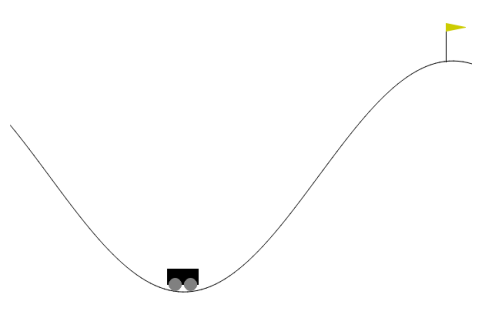

In [30]:
img = env.render() # how the environment looks in the current state, you can use the render method.

plt.figure(figsize=(6, 4))
plt.imshow(img)
plt.axis("off")
plt.show()

In [33]:
def render(env):
    img = env.render() # how the environment looks in the current state, you can use the render method.
    plt.figure(figsize=(6, 4))
    plt.imshow(img)
    plt.axis("off")
    plt.show()

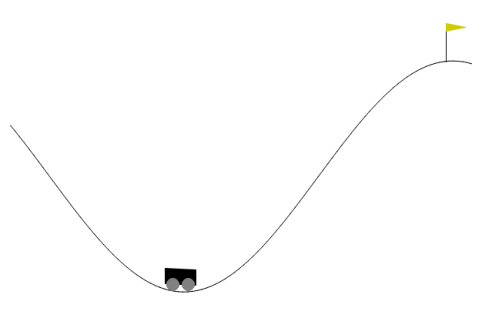

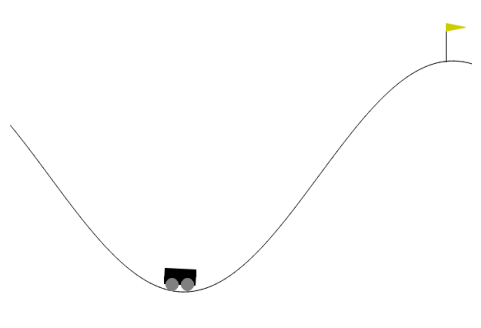

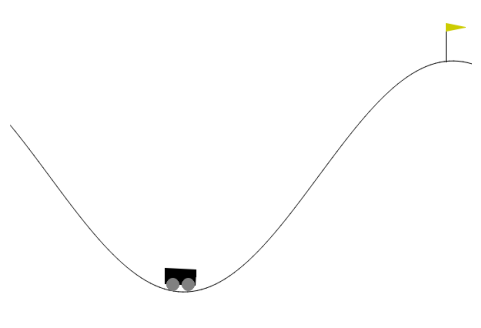

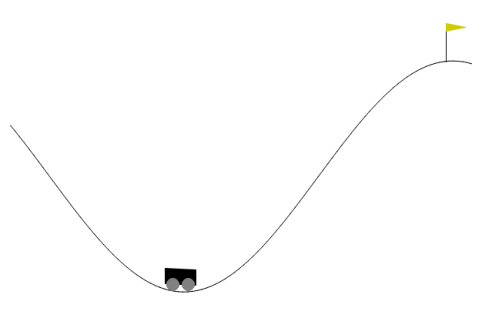

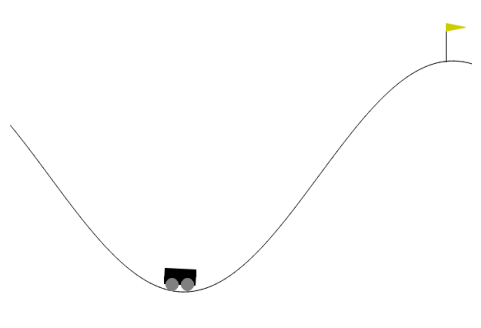

...

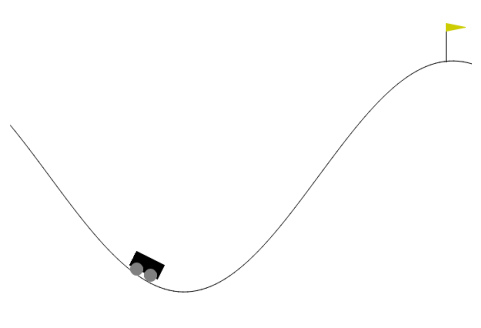

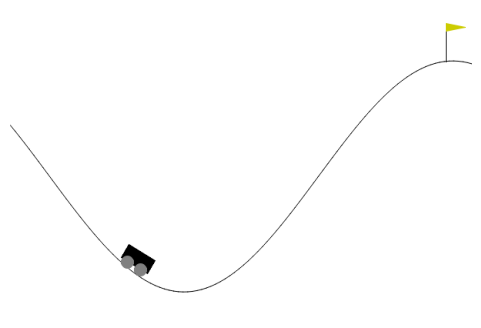

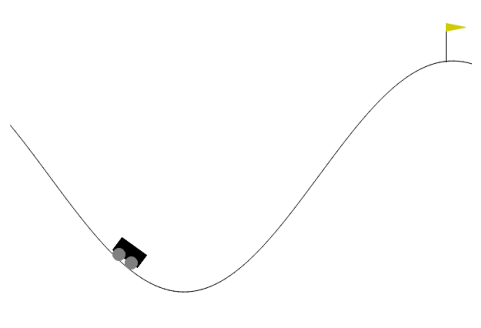

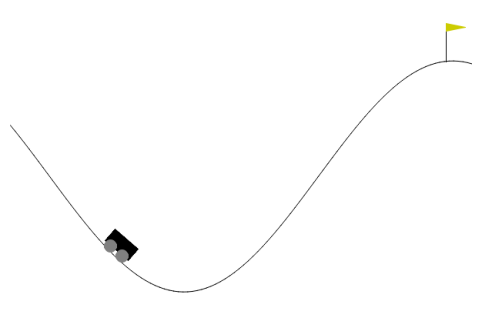

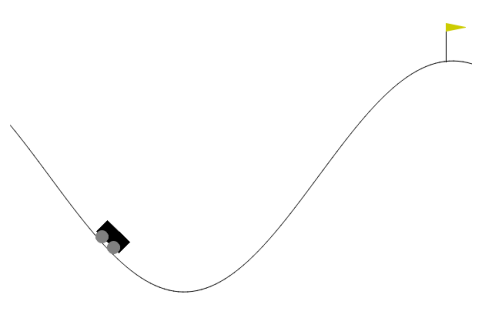

KeyboardInterrupt: 

<Figure size 600x400 with 0 Axes>

In [34]:
# ## typical code 
# import time 

# # Number of steps you run the agent for 
# num_steps = 1500

# obs = env.reset()

# for step in range(num_steps):
#     # take random action, but you can also do something more intelligent
#     # action = my_intelligent_agent_fn(obs) 
#     action = env.action_space.sample()
    
#     # apply the action
#     obs, reward, done, info, _  = env.step(action)
    
#     # Render the env
#     render(env)

#     # Wait a bit before the next frame unless you want to see a crazy fast video
#     time.sleep(0.001)
    
#     # If the epsiode is up, then start another one
#     if done:
#         env.reset()

# # Close the env
# env.close()

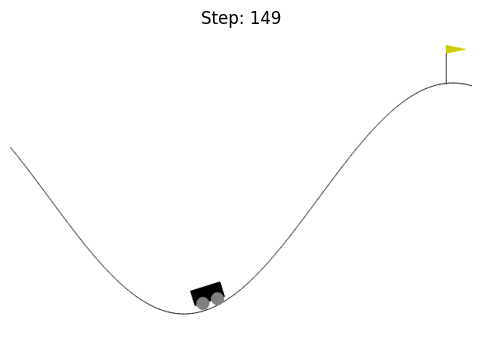

In [35]:
import time
from IPython.display import display, clear_output

# Number of steps you run the agent for
num_steps = 150
obs = env.reset()

fig, ax = plt.subplots(figsize=(6, 4))

for step in range(num_steps):
    action = env.action_space.sample()
    obs, reward, done, info, _ = env.step(action)
    
    # Grab the current frame
    img = env.render()
    
    # Clear previous frame and update the plot in place
    ax.clear()
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(f"Step: {step}")
    
    display(fig)
    clear_output(wait=True)
    time.sleep(0.01)
    
    if done:
        obs = env.reset()

plt.close(fig)
env.close()

### Spaces

In [36]:
type(env.observation_space) # The Box(n,) space represents an n-dimensional continuous space
# OUTPUT -> gym.spaces.box.Box 

gym.spaces.box.Box

In [37]:
# the space is bounded meaning that it has its lower(minimum) % upper bound(maximum )
print("Upper Bound for Env Observation", env.observation_space.high)
print("Lower Bound for Env Observation", env.observation_space.low)

Upper Bound for Env Observation [0.6  0.07]
Lower Bound for Env Observation [-1.2  -0.07]


In [39]:
## The Discrete(n) box describes a discrete space with [0…n-1] possible values. In our case, n = 3, meaning our actions can take values of either 0, 1, or 2. 
## Unlike Box, Discrete does not have a high and low method, since, by the very definition, it is clear what type of values are allowed.
# Works 
env.step(2)
print("It works!")

# Doesn't work.
# env.step(4) # -> invalid 
print("It works!")

It works!
It works!


### Wrappers 

In [ ]:
## The Wrapper class in OpenAI Gym provides you with the functionality to modify various parts of an environment to suit your needs. 
### more will explore after 